:::{.callout-note}

This is a preview of server integration with the Modular Inference Engine. **It
is not publicly available yet**.

If you're interested, please [sign up for early
access](https://www.modular.com/get-started).

:::

The Modular Inference Engine works as a drop-in backend for popular model
inference servers, including NVIDIA’s Triton Inference Server and TensorFlow
Serving, as described in the [Server integration overview](/engine/serving/).

This page includes a rendered version of the Jupyter notebook presented by Nick
Kreeger in our [launch keynote video](https://www.modular.com), in which he
shows how you can use our Inference Engine as a drop-in replacement for
TensorFlow inference workloads on a Triton Inference Server instance. We're
sharing this executed version of the notebook so you can look closely at the
code from the video.

## Overview

The code below sends inference requests to two Triton Inference Server
instances running the same BERT large language model:

- The first server is using the default TensorFlow backend for Triton.
- The second server is using the Modular Inference Engine backend for Triton.

As shown in the video, as soon as we call `get_inference_latencies()` to get
results from the Modular backend, the latency numbers in the line plot (at the
bottom of this page) drop dramatically.

A keen viewer will notice differences in the code here, compared to the video.
We’re not trying to trick you; this is just to make the line plot render for
this web page. In the video, we used `jupyterplot` to render the inference
results in real-time. Unfortunately, this kind of plot doesn’t create an image
visible in the notebook output, so we swapped that out for `matplotlib`. That’s
the only difference.

You can also see that we’re using some APIs from a package called
`modular.serving`. This is just a concise higher-level RPC API we
are developing to interact with the Triton Inference Server. We plan to
share this in future, but rest assured that this client API is **not required**
for integration with Triton or TensorFlow Serving. You can use existing
client code as-is with no changes—for an example, see the [Server
integration overview](/engine/serving/).

## Notebook code

In [1]:
from modular.serving.model import ModelOptions
from modular.serving.tensor import RequestedTensor, Tensor
from modular.serving.client import InferenceGrpcClient

# Runtime parameters
host = "localhost"
modular_port = 8001
tensorflow_port = 9001
tensorflow_url = "{}:{}".format(host, tensorflow_port)
modular_url = "{}:{}".format(host, modular_port)

In [2]:
%matplotlib inline
import time
import numpy as np
from matplotlib import pyplot as plt

# Model-specific parameters
model_options = ModelOptions("bert-large")
requested = RequestedTensor.from_names(["end_logits", "start_logits"]) # <- bert-large  
inputs = [
    Tensor("attention_mask", np.ones(shape=(1, 256), dtype=np.int32)),
    Tensor("input_ids", np.ones(shape=(1, 256), dtype=np.int32)),
    Tensor("token_type_ids", np.ones(shape=(1, 256), dtype=np.int32)),
]


# Set up a plotter to run a series of inference requests against a provided triton backend
def get_inference_latencies(triton_client):
    latencies = []
    for x in range(30):
        # Time the request latency
        start = time.time_ns()
        triton_client.infer(model_options, inputs, requested)
        latency_ms = (time.time_ns() - start) / 1_000_000
        latencies.append(latency_ms)
    return latencies

def plot_latencies(latencies):
    plt.ylim((0,800))
    plt.ylabel("Inference Latency")
    plt.xlabel("Request #")
    plt.plot(latencies)
    plt.show()

### Start with Triton running the stock TensorFlow backend

In [3]:
tf_triton_client = InferenceGrpcClient(url=tensorflow_url)

# Run 30 requests, store latency for each request
tf_latencies = get_inference_latencies(tf_triton_client)

### Now switch to sending requests to the Modular backend

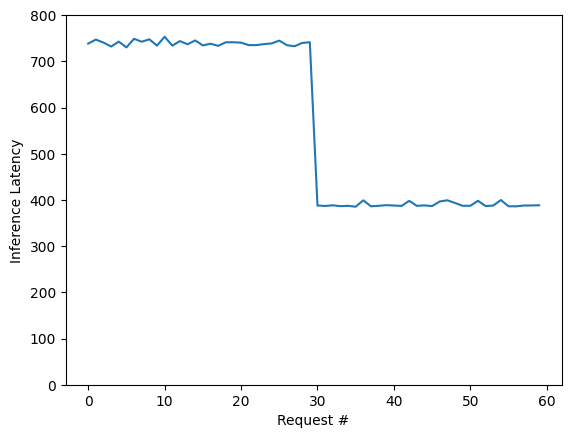

In [4]:
modular_triton_client = InferenceGrpcClient(url=modular_url)

# Run 30 requests, store latency for each request
modular_latencies = get_inference_latencies(modular_triton_client)

# Plot tensorflow and modular latencies in the same plot
plot_latencies(tf_latencies + modular_latencies)